## Logistic Regression
Logistic Regression is a supervised machine learning algorithm used for classification problems. 

<ul>
<li>It is used for binary classification where the output can be one of two possible categories such as Yes/No, True/False or 0/1.</li>
<li>It uses sigmoid function to convert inputs into a probability value between 0 and 1.</li>
</ul>

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv('insurance_data.csv')
df.head()

,age,has_insurance
0,18,0
1,19,0
2,20,0
3,22,0
4,23,0


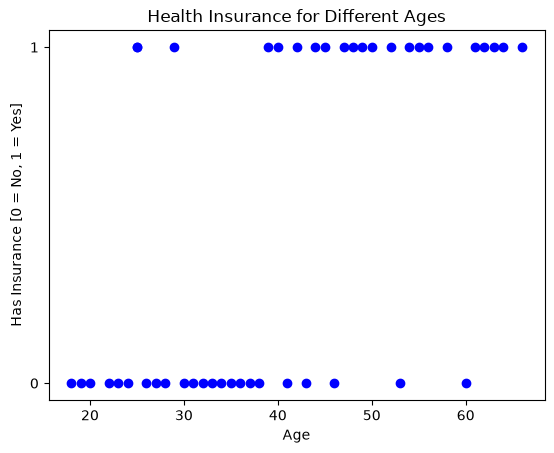

In [8]:
plt.scatter(df.age, df.has_insurance, marker='o', color='blue')
plt.xlabel('Age')
plt.ylabel('Has Insurance [0 = No, 1 = Yes]')
plt.title('Health Insurance for Different Ages')
plt.yticks([0, 1])
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

X = df[['age']]
y = df['has_insurance']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [18]:
data = pd.DataFrame({'age': [90, 0, 75, 50, 60]})
predictions = model.predict(data)

In [ ]:
from pprint import pprint

for age, prediction in zip(data['age'], predictions):
    print(f"Age: {age}, Predicted Insurance Status: {prediction}")


Age: 90, Predicted Insurance Status: 1
Age: 0, Predicted Insurance Status: 0
Age: 75, Predicted Insurance Status: 1
Age: 50, Predicted Insurance Status: 1
Age: 60, Predicted Insurance Status: 1


In [23]:
model.predict_proba(data)

array([[0.00204422, 0.99795578],
       [0.99171425, 0.00828575],
       [0.01259938, 0.98740062],
       [0.21204325, 0.78795675],
       [0.07363397, 0.92636603]])

In [24]:
model.coef_

array([[0.121951]])

In [25]:
model.intercept_

array([-4.78489728])

In [28]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def prediction_func(age):
    z = model.coef_[0][0] * age + model.intercept_[0]
    y = sigmoid(z)
    ans = print(f"Age: {age}, Predicted Probability of Having Insurance: {y}")
    return ans

In [32]:
prediction_func(110)

Age: 110, Predicted Probability of Having Insurance: 0.9998213160487542
